# ERA5 — NOFE figures

Figures for NOFE on the same inputs as the existing NOFE figure notebooks:

1. Patch stitching (4 vertical strips, 2019-07-01)
2. Patch gluing (2 overlapping patches, 2019-01-10)
3. Super resolution (regular-grid source → query nodes, 2019-01-11)
4. 2D embedding scatter (2019-01-15)

PNGs are written to `figures/nofe/`.

In [1]:
# torch, faiss (graph construction) and numba-based libs in one process can make macOS abort
# with a duplicate-OpenMP-runtime error; cap thread pools before importing them.
import os
os.environ.setdefault('KMP_DUPLICATE_LIB_OK', 'TRUE')
os.environ.setdefault('OMP_NUM_THREADS', '1')
os.environ.setdefault('MKL_NUM_THREADS', '1')
os.environ.setdefault('OPENBLAS_NUM_THREADS', '1')
os.environ.setdefault('NUMEXPR_NUM_THREADS', '1')
os.environ.setdefault('NUMBA_NUM_THREADS', '1')

import sys
import subprocess
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from scipy.interpolate import LinearNDInterpolator

from plot_utils_era5 import rgb, rgb_scale

project_root = Path.cwd().parent.parent
sys.path.insert(0, str(project_root / 'src'))
sys.path.insert(0, str(project_root / 'ERA5' / 'scripts'))

from utilities import KernelNN, KernelNN_subgraph, setup_device
from utilities_era5 import ERA5_Graph_Generator as Data_Generator

data_path = project_root / 'ERA5' / 'data'
device = setup_device()
print(f'Using device: {device}')

MODEL_NAME = 'nofe'
FIG_DIR = Path.cwd() / 'figures' / MODEL_NAME
FIG_DIR.mkdir(parents=True, exist_ok=True)


def save_fig(fig, name):
    fig.savefig(FIG_DIR / f'{name}.png', dpi=300, bbox_inches='tight')
    print(f'saved {FIG_DIR / name}.png')


using Device: mps
Using device: mps


## Configuration

In [2]:
# Same inputs as the existing NOFE figure notebooks (patch_stitching.ipynb,
# patch_stitching_withOverlap.ipynb, visualize.ipynb, visualize_subgraph.ipynb).
# Region / graph settings of the regular (full-region) model config:
config = {
    'lat_min': 30, 'lat_max': 75, 'lon_min': -12, 'lon_max': 33,
    'k': 10, 'perplexity': 10, 'sampling_method': 'random', 'feature_mode': 'channel_only',
    'vars': ['w', 'v', 'z', 'q', 'r', 't', 'd', 'o3', 'pv', 'u', 'vo'],
}
lat_min, lat_max, lon_min, lon_max = config['lat_min'], config['lat_max'], config['lon_min'], config['lon_max']
k, perplexity, sampling_method = config['k'], config['perplexity'], config['sampling_method']
feature_mode, vars = config['feature_mode'], config['vars']

# Super-resolution (subgraph) settings:
sr_config = {
    'lat_min': 30, 'lat_max': 70, 'lon_min': -10, 'lon_max': 30,
    'k_in': 5, 'k_out': 5, 'k_cross': 5, 'perplexity': 20, 'interpolate_graph_features': True,
}

Generator = Data_Generator(data_path)


## Model

In [3]:
# Trained checkpoints (same architectures as in the rebuttal notebooks)
model = KernelNN(width=64, ker_width=16, depth=3, ker_in=7, in_width=11, out_width=3).to(device)
model.load_state_dict(torch.load(project_root / 'ERA5' / 'notebooks' / 'regular_papermodel2_2026-05-04_t12-01-43.pth', map_location=device))
model.eval()

sr_model = KernelNN_subgraph(width=64, ker_width=64, depth=2, ker_in=7, known_node_dim=11, unknown_node_dim=11, out_width=3).to(device)
sr_model.load_state_dict(torch.load(project_root / 'ERA5' / 'notebooks' / 'subgraph_tkernel_base2_d2_2026-04-25_t13-59-37.pth', map_location=device))
sr_model.eval()
print('NOFE models loaded.')


def embed(sample, n_components=3):
    """Per-graph embedding used by patch stitching / gluing / 2D scatter."""
    with torch.no_grad():
        Y = model(sample).detach().cpu().numpy()
    if n_components == 3:
        return Y
    # NOFE's output head is 3D; project to the requested dimension with PCA for the 2D scatter
    from sklearn.decomposition import PCA
    return PCA(n_components=n_components).fit_transform(Y)


def predict_superres(cross_sample):
    """NOFE predicts directly at the query (target) nodes."""
    with torch.no_grad():
        return sr_model(cross_sample).detach().cpu().numpy()


NOFE models loaded.


## 1. Patch stitching

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.33423269377585124..1.980385643890963].


saved /Users/siche9897/Github/NOFE/ERA5/notebooks/figures/nofe/patch_stitching.png


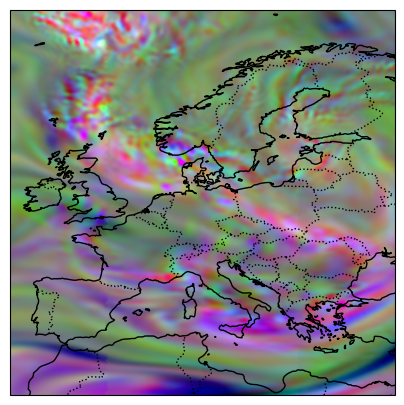

In [4]:
# 4 vertical longitude strips over the full lat range, each embedded independently
date = "2019-07-01"
N = 8000

lon_step = (lon_max - lon_min) / 4
bboxes = [(lon_min + i * lon_step, lat_min, lon_min + (i + 1) * lon_step, lat_max) for i in range(4)]

locations_list, pred_list = [], []
for bbox in bboxes:
    Generator.load_data(bbox=bbox, vars=vars, filename=f'{date}.nc')
    graph = Generator.sample_graph(N=N, k=k, perplexity=perplexity, sampling_method=sampling_method,
                                   gen_feature_mode=feature_mode, sigma_method='ones').to(device)
    locations_list.append(graph.meta.gps)
    print(f'{MODEL_NAME}: embedding strip with {graph.normed_values.shape[0]} points ...', end='\r')
    pred_list.append(embed(graph))

locations = pd.DataFrame(np.vstack(locations_list), columns=['lat', 'lon'])
pred_combined = pd.concat([locations, pd.DataFrame(np.vstack(pred_list), columns=['x1', 'x2', 'x3'])], axis=1)

fig = rgb_scale(pred_combined, percentile=.5, figsize=(5, 5))
save_fig(fig, 'patch_stitching')


## 2. Patch gluing

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.0002562099463112077..1.0712389357140364].


saved /Users/siche9897/Github/NOFE/ERA5/notebooks/figures/nofe/patch_gluing.png


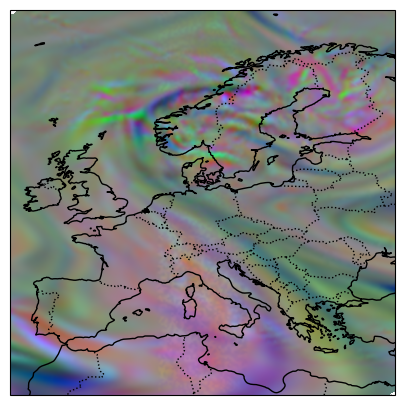

In [5]:
# 2 patches overlapping by 2*margin degrees of longitude, each embedded independently
date = "2019-01-10"
N = 10000
margin = 5

lat_range = (lat_max - lat_min) / 2
lon_range = (lon_max - lon_min) / 2
bboxes = [
    (lon_min, lat_min, lon_max - lon_range + margin, lat_max),
    (lon_min + lon_range - margin, lat_min, lon_max, lat_max),
]

locations_list, pred_list = [], []
for bbox in bboxes:
    Generator.load_data(bbox=bbox, vars=vars, filename=f'{date}.nc')
    graph = Generator.sample_graph(N=N, k=k, perplexity=perplexity, sampling_method=sampling_method,
                                   gen_feature_mode=feature_mode, sigma_method='ones').to(device)
    locations_list.append(graph.meta.gps)
    print(f'{MODEL_NAME}: embedding patch with {graph.normed_values.shape[0]} points ...', end='\r')
    pred_list.append(embed(graph))

locations = pd.DataFrame(np.vstack(locations_list), columns=['lat', 'lon'])
pred_combined = pd.concat([locations, pd.DataFrame(np.vstack(pred_list), columns=['x1', 'x2', 'x3'])], axis=1)

fig = rgb(pred_combined, figsize=(5, 5))
save_fig(fig, 'patch_gluing')


## 3. Super resolution

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.022989071143053843..1.015879369761838].


saved /Users/siche9897/Github/NOFE/ERA5/notebooks/figures/nofe/super_resolution.png


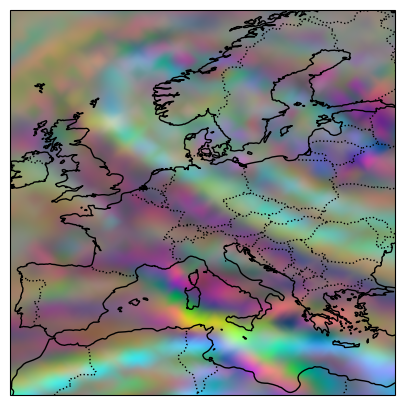

In [6]:
# 1000 regular-grid source nodes -> 1000 regular-grid query nodes (visualize_subgraph.ipynb setup)
date = "2019-01-11"
N_in, N_out = 1000, 1000

sr_bbox = sr_config['lon_min'], sr_config['lat_min'], sr_config['lon_max'], sr_config['lat_max']
Generator.load_data(bbox=sr_bbox, vars=vars, filename=f'{date}.nc')

in_graph = Generator.sample_graph(N=N_in, k=sr_config['k_in'], perplexity=sr_config['perplexity'],
                                  sampling_method='regular_subset', gen_feature_mode=feature_mode)
out_graph = Generator.sample_graph(N=N_out, k=sr_config['k_out'], perplexity=sr_config['perplexity'],
                                   sampling_method='regular_subset', gen_feature_mode=feature_mode)
cross_graph = Generator.connect_graphs(in_graph=in_graph, out_graph=out_graph, k_cross=sr_config['k_cross'])
cross_graph["x"] = Generator.construct_output_node_features(
    cross_graph=cross_graph, interpolate=sr_config['interpolate_graph_features'], gen_feature_mode=feature_mode)
cross_sample = cross_graph.to(device)

pred = predict_superres(cross_sample)

locations = pd.DataFrame({"lat": cross_sample.target.meta.gps[:, 0], "lon": cross_sample.target.meta.gps[:, 1]})
res = pd.concat([locations, pd.DataFrame(pred, columns=['x1', 'x2', 'x3'])], axis=1)

fig = rgb(res, figsize=(5, 5))
save_fig(fig, 'super_resolution')


## 4. 2D embedding scatter

/Users/siche9897/miniconda3/envs/neural-operators-new/lib/python3.10/site-packages/sklearn/decomposition/_base.py:148: RuntimeWarning: divide by zero encountered in matmul
  X_transformed = X @ self.components_.T
/Users/siche9897/miniconda3/envs/neural-operators-new/lib/python3.10/site-packages/sklearn/decomposition/_base.py:148: RuntimeWarning: overflow encountered in matmul
  X_transformed = X @ self.components_.T
/Users/siche9897/miniconda3/envs/neural-operators-new/lib/python3.10/site-packages/sklearn/decomposition/_base.py:148: RuntimeWarning: invalid value encountered in matmul
  X_transformed = X @ self.components_.T


saved /Users/siche9897/Github/NOFE/ERA5/notebooks/figures/nofe/embedding_2d_scatter.png


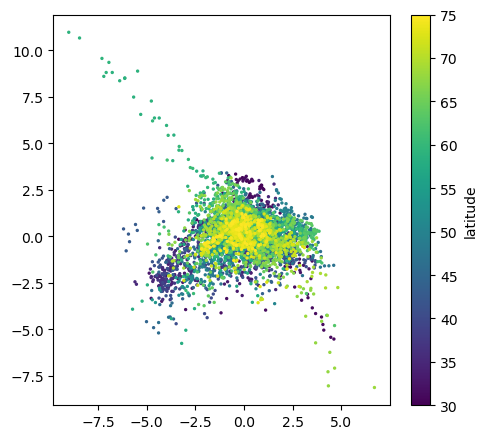

In [7]:
# 2D embedding of one full-region graph, points coloured by latitude
date = "2019-01-15"
N_SCATTER = 5000  # visualize.ipynb used 30000; kept smaller so all baselines (SpatialPCA, Concord) stay tractable

Generator.load_data(bbox=(lon_min, lat_min, lon_max, lat_max), vars=vars, filename=f'{date}.nc')
graph = Generator.sample_graph(N=N_SCATTER, k=k, perplexity=perplexity, sampling_method=sampling_method,
                               gen_feature_mode=feature_mode, sigma_method='ones').to(device)

Y2 = embed(graph, n_components=2)
gps = np.array(graph.meta.gps)  # columns: [lat, lon]

fig, ax = plt.subplots(figsize=(5, 4.5))
sc = ax.scatter(Y2[:, 0], Y2[:, 1], c=gps[:, 0], s=2, cmap='viridis')
fig.colorbar(sc, ax=ax, label='latitude')
plt.tight_layout()
save_fig(fig, 'embedding_2d_scatter')
